In [2]:
import os
from dotenv import load_dotenv
from sqlalchemy import create_engine

# Load credentials from .env
load_dotenv()

DB_HOST = os.getenv("DB_HOST", "localhost")
DB_PORT = os.getenv("DB_PORT", "3306")
DB_NAME = os.getenv("DB_NAME", "saas_analytics")
DB_USER = os.getenv("DB_USER", "root")
DB_PASSWORD = os.getenv("DB_PASSWORD", "")

# Create the database engine connection
connection_string = f"mysql+pymysql://{DB_USER}:{DB_PASSWORD}@{DB_HOST}:{DB_PORT}/{DB_NAME}"
engine = create_engine(connection_string)

print("Database engine initialized successfully!")

Database engine initialized successfully!


In [8]:
from sqlalchemy import text

create_mrr_view = """
CREATE OR REPLACE VIEW vw_mrr AS
SELECT
    DATE_FORMAT(month_start, '%Y-%m') AS month,
    ROUND(SUM(mrr_value), 2) AS mrr,
    ROUND(SUM(mrr_value) * 12, 2) AS arr
FROM (
    SELECT
        calendar.month_start,
        s.subscription_id,
        CASE
            WHEN s.billing_cycle = 'annual' THEN s.price / 12
            ELSE s.price
        END AS mrr_value
    FROM (
        SELECT DISTINCT
            STR_TO_DATE(
                CONCAT(DATE_FORMAT(start_date, '%Y-%m'), '-01'),
                '%Y-%m-%d'
            ) AS month_start
        FROM subscriptions
        UNION
        SELECT DATE('2023-11-01')
        UNION
        SELECT DATE('2026-10-01')
    ) calendar
    JOIN subscriptions s
      ON s.start_date < DATE_ADD(calendar.month_start, INTERVAL 1 MONTH)
     AND (s.end_date IS NULL OR s.end_date >= calendar.month_start)
) monthly_data
GROUP BY month_start
"""

with engine.begin() as conn:
    conn.execute(text(create_mrr_view))

print("MRR view created successfully!")

MRR view created successfully!


In [9]:
with engine.connect() as conn:
    result = conn.execute(text("SHOW FULL TABLES"))
    for row in result:
        print(row)

('customers', 'BASE TABLE')
('marketing_spend', 'BASE TABLE')
('payments', 'BASE TABLE')
('plan_changes', 'BASE TABLE')
('subscriptions', 'BASE TABLE')
('usage_engagement', 'BASE TABLE')
('vw_mrr', 'VIEW')


In [10]:
import pandas as pd

with engine.connect() as conn:
    mrr_df = pd.read_sql(
        text("SELECT * FROM vw_mrr ORDER BY month"),
        conn
    )

display(mrr_df.head())
print("Rows:", len(mrr_df))

,month,mrr,arr
0,2023-11,12486.33,149836.0
1,2023-12,26551.67,318620.0
2,2024-01,46324.67,555896.0
3,2024-02,62960.17,755522.0
4,2024-03,79017.67,948212.0


Rows: 36


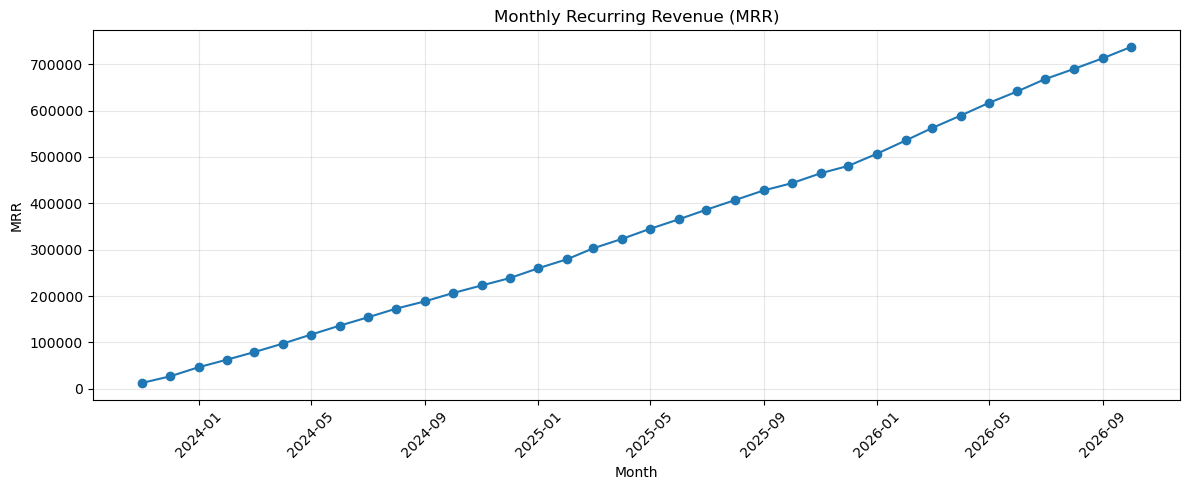

In [11]:
import matplotlib.pyplot as plt

mrr_df["month"] = pd.to_datetime(mrr_df["month"] + "-01")

plt.figure(figsize=(12, 5))
plt.plot(mrr_df["month"], mrr_df["mrr"], marker="o")
plt.title("Monthly Recurring Revenue (MRR)")
plt.xlabel("Month")
plt.ylabel("MRR")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [12]:
from sqlalchemy import text

with engine.begin() as conn:
    conn.execute(text("""
        CREATE OR REPLACE VIEW vw_arr AS
        SELECT
            subscription_id,
            customer_id,
            plan,
            billing_cycle,
            price,
            CASE
                WHEN billing_cycle = 'monthly' THEN price * 12
                WHEN billing_cycle = 'annual' THEN price
                ELSE 0
            END AS arr
        FROM subscriptions
        WHERE status = 'active'
    """))

print("vw_arr created successfully!")

vw_arr created successfully!


In [13]:
with engine.begin() as conn:
    conn.execute(text("""
        CREATE OR REPLACE VIEW vw_churn AS
        SELECT
            DATE_FORMAT(m.month_start, '%Y-%m') AS month,
            COUNT(DISTINCT CASE
                WHEN s.end_date >= m.month_start
                 AND s.end_date < DATE_ADD(
                     m.month_start, INTERVAL 1 MONTH
                 )
                THEN s.subscription_id
            END) AS cancelled_subscriptions,

            COUNT(DISTINCT CASE
                WHEN s.start_date < m.month_start
                 AND (s.end_date IS NULL
                      OR s.end_date >= m.month_start)
                THEN s.subscription_id
            END) AS starting_subscriptions,

            ROUND(
                100.0 * COUNT(DISTINCT CASE
                    WHEN s.end_date >= m.month_start
                     AND s.end_date < DATE_ADD(
                         m.month_start, INTERVAL 1 MONTH
                     )
                    THEN s.subscription_id
                END)
                / NULLIF(COUNT(DISTINCT CASE
                    WHEN s.start_date < m.month_start
                     AND (s.end_date IS NULL
                          OR s.end_date >= m.month_start)
                    THEN s.subscription_id
                END), 0),
                2
            ) AS churn_rate
        FROM (
            SELECT DISTINCT
                DATE_FORMAT(start_date, '%Y-%m-01') AS month_start
            FROM subscriptions

            UNION

            SELECT DISTINCT
                DATE_FORMAT(end_date, '%Y-%m-01') AS month_start
            FROM subscriptions
            WHERE end_date IS NOT NULL
        ) m
        LEFT JOIN subscriptions s
            ON s.start_date < DATE_ADD(
                m.month_start, INTERVAL 1 MONTH
            )
        GROUP BY m.month_start
    """))

print("vw_churn created successfully!")

vw_churn created successfully!


In [14]:
with engine.begin() as conn:
    conn.execute(text("""
        CREATE OR REPLACE VIEW vw_cac AS
        SELECT
            m.month,
            m.channel,
            m.spend,
            COALESCE(c.new_customers, 0) AS new_customers,
            ROUND(
                m.spend / NULLIF(c.new_customers, 0), 2
            ) AS cac
        FROM marketing_spend m
        LEFT JOIN (
            SELECT
                DATE_FORMAT(signup_date, '%Y-%m') AS month,
                acquisition_channel AS channel,
                COUNT(*) AS new_customers
            FROM customers
            GROUP BY
                DATE_FORMAT(signup_date, '%Y-%m'),
                acquisition_channel
        ) c
            ON c.month = m.month
           AND c.channel = m.channel
    """))

print("vw_cac created successfully!")

vw_cac created successfully!


In [15]:
with engine.begin() as conn:
    conn.execute(text("""
        CREATE OR REPLACE VIEW vw_payment_health AS
        SELECT
            DATE_FORMAT(payment_date, '%Y-%m') AS month,
            payment_status,
            COUNT(*) AS payment_count,
            ROUND(SUM(amount), 2) AS total_amount
        FROM payments
        GROUP BY
            DATE_FORMAT(payment_date, '%Y-%m'),
            payment_status
    """))

print("vw_payment_health created successfully!")

vw_payment_health created successfully!


In [16]:
with engine.connect() as conn:
    result = conn.execute(text("""
        SHOW FULL TABLES
        WHERE Table_type = 'VIEW'
    """))

    for row in result.fetchall():
        print(row)

('vw_arr', 'VIEW')
('vw_cac', 'VIEW')
('vw_churn', 'VIEW')
('vw_mrr', 'VIEW')
('vw_payment_health', 'VIEW')


In [17]:
import pandas as pd
from sqlalchemy import text

view_names = [
    "vw_mrr",
    "vw_arr",
    "vw_churn",
    "vw_cac",
    "vw_payment_health"
]

for view in view_names:
    with engine.connect() as conn:
        df = pd.read_sql(
            text(f"SELECT * FROM `{view}` LIMIT 5"),
            conn
        )

    print(f"\n--- {view} ---")
    display(df)


--- vw_mrr ---


,month,mrr,arr
0,2023-11,12486.33,149836.0
1,2026-08,690025.50,8280306.0
2,2024-08,172918.17,2075018.0
3,2023-12,26551.67,318620.0
4,2024-10,206405.17,2476862.0



--- vw_arr ---


,subscription_id,customer_id,plan,billing_cycle,price,arr
0,SUB0000004,CUST000766,Enterprise,monthly,249.0,2988.0
1,SUB0000005,CUST006737,Pro,monthly,79.0,948.0
2,SUB0000008,CUST003503,Pro,monthly,79.0,948.0
3,SUB0000009,CUST007974,Basic,monthly,29.0,348.0
4,SUB0000010,CUST004315,Pro,monthly,79.0,948.0



--- vw_churn ---


,month,cancelled_subscriptions,starting_subscriptions,churn_rate
0,2023-11,0,0,NaN
1,2023-12,4,157,2.55
2,2024-01,4,332,1.20
3,2024-02,15,555,2.70
4,2024-03,16,746,2.14



--- vw_cac ---


,month,channel,spend,new_customers,cac
0,2023-11-01,Email,2205.38,0,None
1,2023-11-01,Organic,3191.14,0,None
2,2023-11-01,Paid Search,12965.11,0,None
3,2023-11-01,Referral,2906.81,0,None
4,2023-11-01,Social,7200.07,0,None



--- vw_payment_health ---


,month,payment_status,payment_count,total_amount
0,2023-11,success,148,30661.0
1,2024-11,success,1903,226960.0
2,2023-12,success,288,72626.0
3,2024-01,success,447,89106.0
4,2024-02,success,581,92901.0


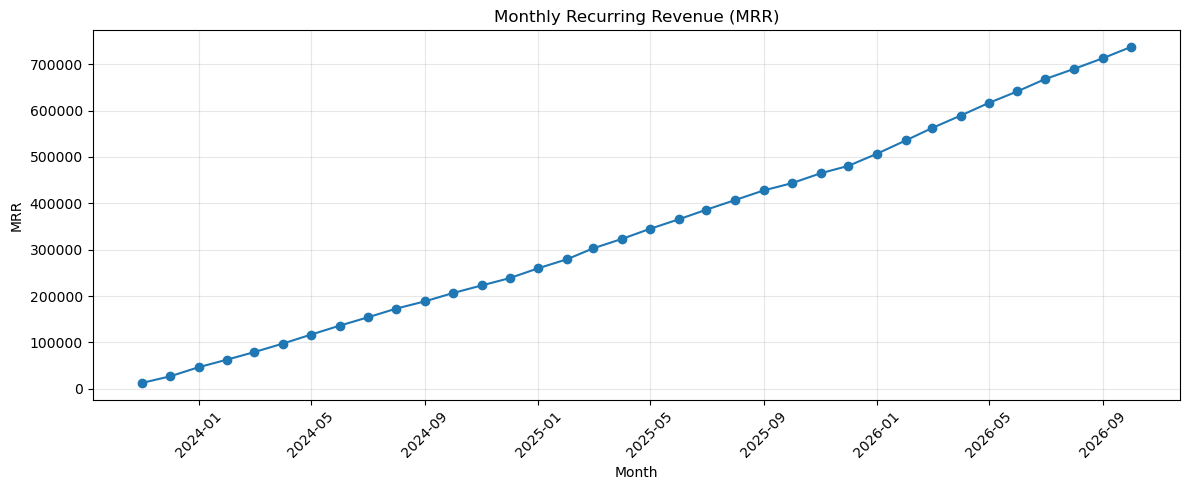

In [18]:
import matplotlib.pyplot as plt
import pandas as pd
from sqlalchemy import text

with engine.connect() as conn:
    mrr_df = pd.read_sql(
        text("SELECT * FROM vw_mrr ORDER BY month"),
        conn
    )

mrr_df["month"] = pd.to_datetime(mrr_df["month"])

plt.figure(figsize=(12, 5))
plt.plot(mrr_df["month"], mrr_df["mrr"], marker="o")
plt.title("Monthly Recurring Revenue (MRR)")
plt.xlabel("Month")
plt.ylabel("MRR")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [19]:
import pandas as pd
import matplotlib.pyplot as plt
from sqlalchemy import text

with engine.connect() as conn:
    arr_df = pd.read_sql(
        text("SELECT * FROM vw_arr"),
        conn
    )

display(arr_df.head())
print("Total records:", len(arr_df))
print("Columns:", arr_df.columns.tolist())

,subscription_id,customer_id,plan,billing_cycle,price,arr
0,SUB0000004,CUST000766,Enterprise,monthly,249.0,2988.0
1,SUB0000005,CUST006737,Pro,monthly,79.0,948.0
2,SUB0000008,CUST003503,Pro,monthly,79.0,948.0
3,SUB0000009,CUST007974,Basic,monthly,29.0,348.0
4,SUB0000010,CUST004315,Pro,monthly,79.0,948.0


Total records: 6707
Columns: ['subscription_id', 'customer_id', 'plan', 'billing_cycle', 'price', 'arr']


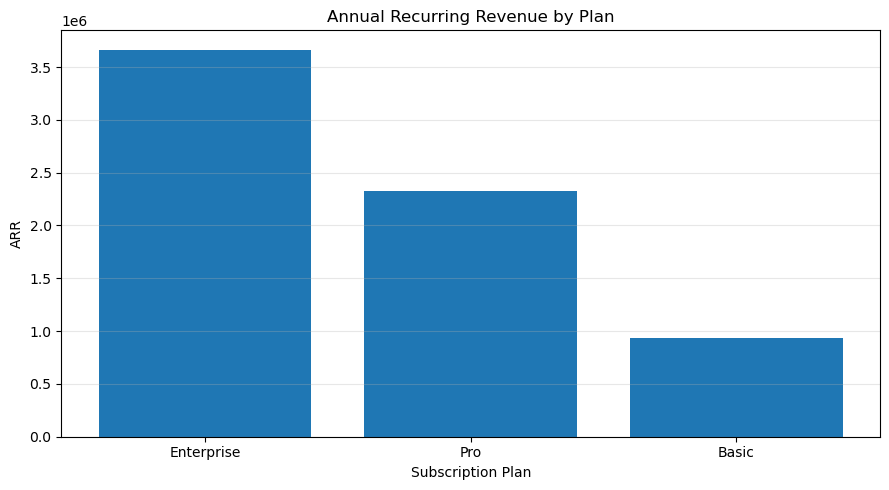

,plan,arr
1,Enterprise,3664284.0
2,Pro,2324970.0
0,Basic,934728.0


In [20]:
arr_by_plan = (
    arr_df.groupby("plan", as_index=False)["arr"]
    .sum()
    .sort_values("arr", ascending=False)
)

plt.figure(figsize=(9, 5))
plt.bar(arr_by_plan["plan"], arr_by_plan["arr"])
plt.title("Annual Recurring Revenue by Plan")
plt.xlabel("Subscription Plan")
plt.ylabel("ARR")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

display(arr_by_plan)

In [21]:
with engine.connect() as conn:
    churn_df = pd.read_sql(
        text("SELECT * FROM vw_churn ORDER BY month"),
        conn
    )

display(churn_df.head())

,month,cancelled_subscriptions,starting_subscriptions,churn_rate
0,2023-11,0,0,NaN
1,2023-12,4,157,2.55
2,2024-01,4,332,1.20
3,2024-02,15,555,2.70
4,2024-03,16,746,2.14


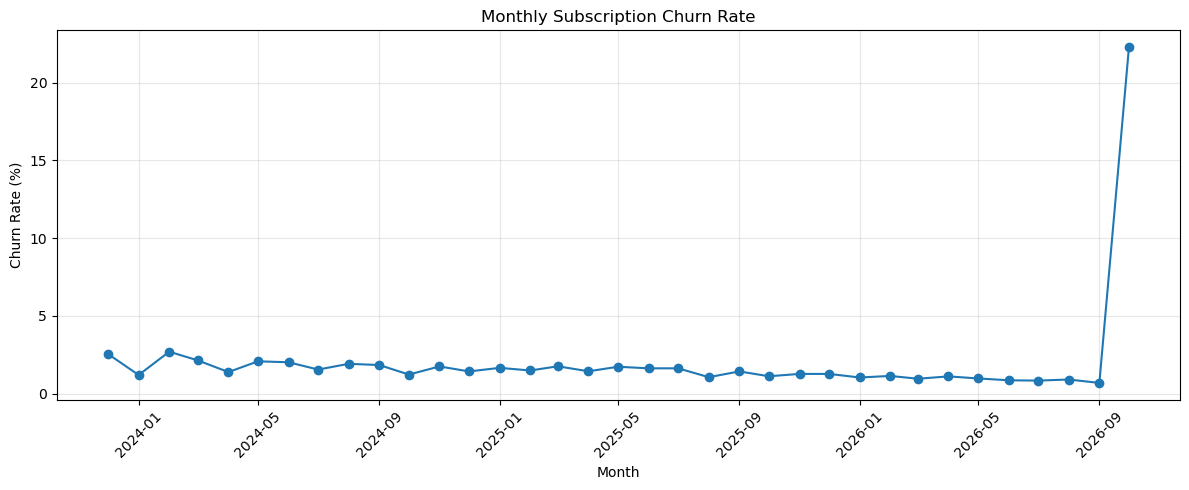

In [22]:
churn_df["month"] = pd.to_datetime(churn_df["month"])

plt.figure(figsize=(12, 5))
plt.plot(
    churn_df["month"],
    churn_df["churn_rate"],
    marker="o"
)

plt.title("Monthly Subscription Churn Rate")
plt.xlabel("Month")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [23]:
with engine.connect() as conn:
    cac_df = pd.read_sql(
        text("SELECT * FROM vw_cac ORDER BY month, channel"),
        conn
    )

display(cac_df.head())

,month,channel,spend,new_customers,cac
0,2023-11-01,Email,2205.38,0,None
1,2023-11-01,Organic,3191.14,0,None
2,2023-11-01,Paid Search,12965.11,0,None
3,2023-11-01,Referral,2906.81,0,None
4,2023-11-01,Social,7200.07,0,None


In [24]:
cac_by_channel = (
    cac_df.groupby("channel", as_index=False)
    .agg(
        total_spend=("spend", "sum"),
        new_customers=("new_customers", "sum")
    )
)

cac_by_channel["cac"] = (
    cac_by_channel["total_spend"]
    / cac_by_channel["new_customers"].replace(0, float("nan"))
)

display(cac_by_channel.sort_values("cac"))

,channel,total_spend,new_customers,cac
0,Email,122617.78,0,NaN
1,Organic,200199.87,0,NaN
2,Paid Search,743967.45,0,NaN
3,Referral,170865.03,0,NaN
4,Social,385064.16,0,NaN


In [25]:
with engine.connect() as conn:
    payment_df = pd.read_sql(
        text("SELECT * FROM vw_payment_health ORDER BY month"),
        conn
    )

display(payment_df.head(10))

,month,payment_status,payment_count,total_amount
0,2023-11,success,148,30661.0
1,2023-11,failed,7,784.0
2,2023-11,refunded,2,108.0
3,2023-12,success,288,72626.0
4,2023-12,failed,17,1714.0
5,2023-12,refunded,1,290.0
6,2024-01,success,447,89106.0
7,2024-01,failed,19,2813.0
8,2024-01,refunded,7,1164.0
9,2024-02,success,581,92901.0


In [26]:
payment_summary = (
    payment_df.groupby("payment_status", as_index=False)
    .agg(
        payment_count=("payment_count", "sum"),
        total_amount=("total_amount", "sum")
    )
)

display(payment_summary)

,payment_status,payment_count,total_amount
0,failed,4373,567160.0
1,refunded,1071,138194.0
2,success,103859,13028269.0


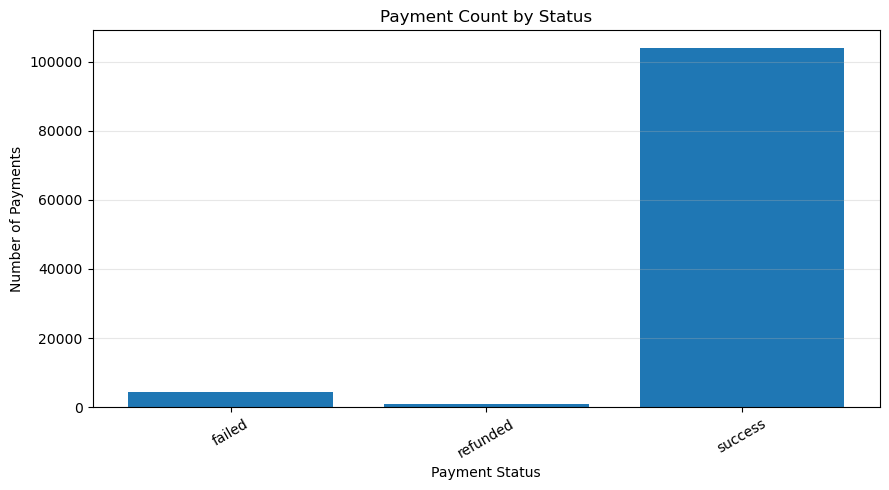

In [27]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.bar(
    payment_summary["payment_status"],
    payment_summary["payment_count"]
)

plt.title("Payment Count by Status")
plt.xlabel("Payment Status")
plt.ylabel("Number of Payments")
plt.xticks(rotation=30)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

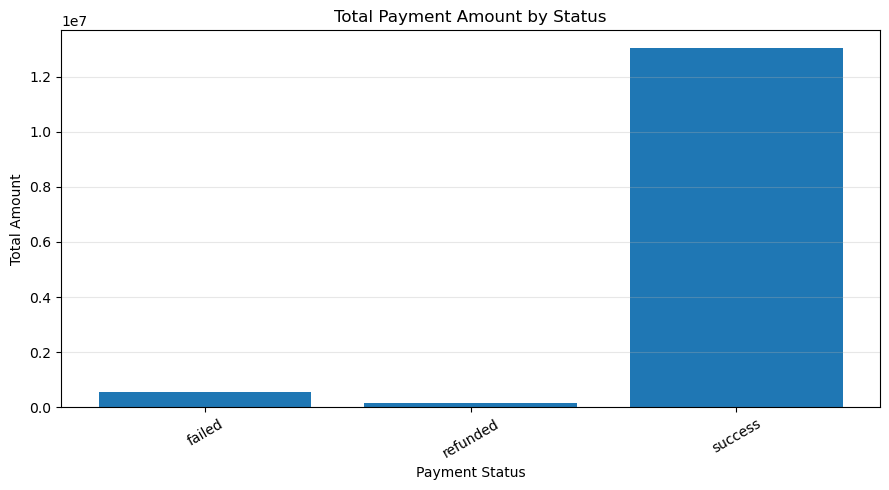

In [28]:
plt.figure(figsize=(9, 5))

plt.bar(
    payment_summary["payment_status"],
    payment_summary["total_amount"]
)

plt.title("Total Payment Amount by Status")
plt.xlabel("Payment Status")
plt.ylabel("Total Amount")
plt.xticks(rotation=30)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [29]:
analysis_results = {
    "MRR": mrr_df,
    "ARR": arr_df,
    "Churn": churn_df,
    "CAC": cac_df,
    "Payment Health": payment_df
}

for name, df in analysis_results.items():
    print(f"\n{name}")
    print("Rows:", len(df))
    print("Columns:", df.columns.tolist())
    print("Missing values:", df.isnull().sum().sum())


MRR
Rows: 36
Columns: ['month', 'mrr', 'arr']
Missing values: 0

ARR
Rows: 6707
Columns: ['subscription_id', 'customer_id', 'plan', 'billing_cycle', 'price', 'arr']
Missing values: 0

Churn
Rows: 36
Columns: ['month', 'cancelled_subscriptions', 'starting_subscriptions', 'churn_rate']
Missing values: 1

CAC
Rows: 180
Columns: ['month', 'channel', 'spend', 'new_customers', 'cac']
Missing values: 180

Payment Health
Rows: 108
Columns: ['month', 'payment_status', 'payment_count', 'total_amount']
Missing values: 0


In [30]:
display(cac_df.head(10))

print("Marketing spend total:", cac_df["spend"].sum())
print("New customers total:", cac_df["new_customers"].sum())
print("Missing new_customers:", cac_df["new_customers"].isna().sum())
print("Missing CAC:", cac_df["cac"].isna().sum())

print("\nNew customers by channel:")
display(
    cac_df.groupby("channel", as_index=False)["new_customers"].sum()
)

,month,channel,spend,new_customers,cac
0,2023-11-01,Email,2205.38,0,None
1,2023-11-01,Organic,3191.14,0,None
2,2023-11-01,Paid Search,12965.11,0,None
3,2023-11-01,Referral,2906.81,0,None
4,2023-11-01,Social,7200.07,0,None
5,2023-12-01,Email,2270.25,0,None
6,2023-12-01,Organic,3598.95,0,None
7,2023-12-01,Paid Search,12904.14,0,None
8,2023-12-01,Referral,3054.10,0,None
9,2023-12-01,Social,8013.54,0,None


Marketing spend total: 1622714.29
New customers total: 0
Missing new_customers: 0
Missing CAC: 180

New customers by channel:


,channel,new_customers
0,Email,0
1,Organic,0
2,Paid Search,0
3,Referral,0
4,Social,0


In [31]:
display(churn_df[churn_df.isna().any(axis=1)])

,month,cancelled_subscriptions,starting_subscriptions,churn_rate
0,2023-11-01,0,0,NaN


In [32]:
display(
    churn_df[
        ["month", "cancelled_subscriptions",
         "starting_subscriptions", "churn_rate"]
    ].tail(10)
)

,month,cancelled_subscriptions,starting_subscriptions,churn_rate
26,2026-01-01,58,5570,1.04
27,2026-02-01,67,5887,1.14
28,2026-03-01,59,6164,0.96
29,2026-04-01,72,6471,1.11
30,2026-05-01,66,6764,0.98
31,2026-06-01,61,7075,0.86
32,2026-07-01,62,7382,0.84
33,2026-08-01,70,7662,0.91
34,2026-09-01,55,7919,0.69
35,2026-10-01,1830,8209,22.29


In [33]:
print("CAC missing values:", cac_df["cac"].isna().sum())
print("Churn missing values:", churn_df["churn_rate"].isna().sum())

CAC missing values: 180
Churn missing values: 1


In [34]:
display(cac_df.head(10))

print("Total spend:", cac_df["spend"].sum())
print("Total new customers:", cac_df["new_customers"].sum())

print("\nMissing values:")
print(cac_df[["spend", "new_customers", "cac"]].isna().sum())

print("\nNew customers by channel:")
display(
    cac_df.groupby("channel", as_index=False)
    .agg(
        spend=("spend", "sum"),
        new_customers=("new_customers", "sum")
    )
)

,month,channel,spend,new_customers,cac
0,2023-11-01,Email,2205.38,0,None
1,2023-11-01,Organic,3191.14,0,None
2,2023-11-01,Paid Search,12965.11,0,None
3,2023-11-01,Referral,2906.81,0,None
4,2023-11-01,Social,7200.07,0,None
5,2023-12-01,Email,2270.25,0,None
6,2023-12-01,Organic,3598.95,0,None
7,2023-12-01,Paid Search,12904.14,0,None
8,2023-12-01,Referral,3054.10,0,None
9,2023-12-01,Social,8013.54,0,None


Total spend: 1622714.29
Total new customers: 0

Missing values:
spend              0
new_customers      0
cac              180
dtype: int64

New customers by channel:


,channel,spend,new_customers
0,Email,122617.78,0
1,Organic,200199.87,0
2,Paid Search,743967.45,0
3,Referral,170865.03,0
4,Social,385064.16,0


In [35]:
from sqlalchemy import text
import pandas as pd

with engine.connect() as conn:
    customer_channels = pd.read_sql(
        text("""
            SELECT acquisition_channel, COUNT(*) AS customers
            FROM customers
            GROUP BY acquisition_channel
            ORDER BY customers DESC
        """),
        conn
    )

display(customer_channels)

,acquisition_channel,customers
0,Paid Search,2796
1,Organic,2672
2,Referral,1764
3,Social,1488
4,Email,1280


In [36]:
with engine.connect() as conn:
    marketing_channels = pd.read_sql(
        text("""
            SELECT channel, COUNT(*) AS records,
                   SUM(spend) AS total_spend
            FROM marketing_spend
            GROUP BY channel
            ORDER BY channel
        """),
        conn
    )

display(marketing_channels)

,channel,records,total_spend
0,Email,36,122617.78
1,Organic,36,200199.87
2,Paid Search,36,743967.45
3,Referral,36,170865.03
4,Social,36,385064.16


In [37]:
with engine.connect() as conn:
    view_definition = conn.execute(
        text("SHOW CREATE VIEW vw_cac")
    ).fetchone()

print(view_definition[1])

CREATE ALGORITHM=UNDEFINED DEFINER=`saas_user`@`localhost` SQL SECURITY DEFINER VIEW `vw_cac` AS select `m`.`month` AS `month`,`m`.`channel` AS `channel`,`m`.`spend` AS `spend`,coalesce(`c`.`new_customers`,0) AS `new_customers`,round((`m`.`spend` / nullif(`c`.`new_customers`,0)),2) AS `cac` from (`marketing_spend` `m` left join (select date_format(`customers`.`signup_date`,'%Y-%m') AS `month`,`customers`.`acquisition_channel` AS `channel`,count(0) AS `new_customers` from `customers` group by date_format(`customers`.`signup_date`,'%Y-%m'),`customers`.`acquisition_channel`) `c` on(((`c`.`month` = `m`.`month`) and (`c`.`channel` = `m`.`channel`))))


In [38]:
from sqlalchemy import text
import pandas as pd

with engine.connect() as conn:
    print("1. Customer channels")
    display(pd.read_sql(
        text("""
            SELECT DISTINCT acquisition_channel
            FROM customers
            ORDER BY acquisition_channel
        """),
        conn
    ))

    print("2. Marketing channels and month formats")
    display(pd.read_sql(
        text("""
            SELECT DISTINCT channel, month
            FROM marketing_spend
            ORDER BY channel, month
            LIMIT 15
        """),
        conn
    ))

    print("3. Customer signup months")
    display(pd.read_sql(
        text("""
            SELECT
                DATE_FORMAT(signup_date, '%Y-%m') AS signup_month,
                acquisition_channel,
                COUNT(*) AS new_customers
            FROM customers
            GROUP BY signup_month, acquisition_channel
            ORDER BY signup_month
            LIMIT 15
        """),
        conn
    ))

1. Customer channels


,acquisition_channel
0,Email
1,Organic
2,Paid Search
3,Referral
4,Social


2. Marketing channels and month formats


,channel,month
0,Email,2023-11-01
1,Email,2023-12-01
2,Email,2024-01-01
3,Email,2024-02-01
4,Email,2024-03-01
5,Email,2024-04-01
6,Email,2024-05-01
7,Email,2024-06-01
8,Email,2024-07-01
9,Email,2024-08-01


3. Customer signup months


,signup_month,acquisition_channel,new_customers
0,2023-11,Email,19
1,2023-11,Organic,50
2,2023-11,Paid Search,38
3,2023-11,Referral,28
4,2023-11,Social,22
5,2023-12,Email,32
6,2023-12,Organic,49
7,2023-12,Paid Search,49
8,2023-12,Referral,27
9,2023-12,Social,22


In [39]:
with engine.begin() as conn:
    conn.execute(text("""
        CREATE OR REPLACE VIEW vw_cac AS
        SELECT
            m.month AS month,
            m.channel AS channel,
            m.spend AS spend,
            COALESCE(c.new_customers, 0) AS new_customers,
            ROUND(
                m.spend / NULLIF(c.new_customers, 0),
                2
            ) AS cac
        FROM marketing_spend AS m
        LEFT JOIN (
            SELECT
                DATE_FORMAT(signup_date, '%Y-%m') AS month,
                acquisition_channel AS channel,
                COUNT(*) AS new_customers
            FROM customers
            GROUP BY
                DATE_FORMAT(signup_date, '%Y-%m'),
                acquisition_channel
        ) AS c
          ON DATE_FORMAT(m.month, '%Y-%m') = c.month
         AND TRIM(m.channel) = TRIM(c.channel)
    """))

print("vw_cac updated successfully.")

vw_cac updated successfully.


In [40]:
with engine.connect() as conn:
    cac_df = pd.read_sql(
        text("SELECT * FROM vw_cac ORDER BY month, channel"),
        conn
    )

display(cac_df.head(10))

print("Total new customers:", cac_df["new_customers"].sum())
print("Missing CAC values:", cac_df["cac"].isna().sum())
print("Zero-customer rows:", (cac_df["new_customers"] == 0).sum())

,month,channel,spend,new_customers,cac
0,2023-11-01,Email,2205.38,19,116.07
1,2023-11-01,Organic,3191.14,50,63.82
2,2023-11-01,Paid Search,12965.11,38,341.19
3,2023-11-01,Referral,2906.81,28,103.81
4,2023-11-01,Social,7200.07,22,327.28
5,2023-12-01,Email,2270.25,32,70.95
6,2023-12-01,Organic,3598.95,49,73.45
7,2023-12-01,Paid Search,12904.14,49,263.35
8,2023-12-01,Referral,3054.10,27,113.11
9,2023-12-01,Social,8013.54,22,364.25


Total new customers: 10000
Missing CAC values: 0
Zero-customer rows: 0


In [41]:
with engine.connect() as conn:
    churn_df = pd.read_sql(
        text("SELECT * FROM vw_churn ORDER BY month"),
        conn
    )

display(churn_df[churn_df["churn_rate"].isna()])

,month,cancelled_subscriptions,starting_subscriptions,churn_rate
0,2023-11,0,0,NaN


In [42]:
print("Missing churn rates:", churn_df["churn_rate"].isna().sum())
print("Total months:", len(churn_df))

Missing churn rates: 1
Total months: 36


,channel,total_spend,total_customers,cac
1,Organic,200199.87,2672,74.925101
0,Email,122617.78,1280,95.795141
3,Referral,170865.03,1764,96.862262
4,Social,385064.16,1488,258.779677
2,Paid Search,743967.45,2796,266.082779


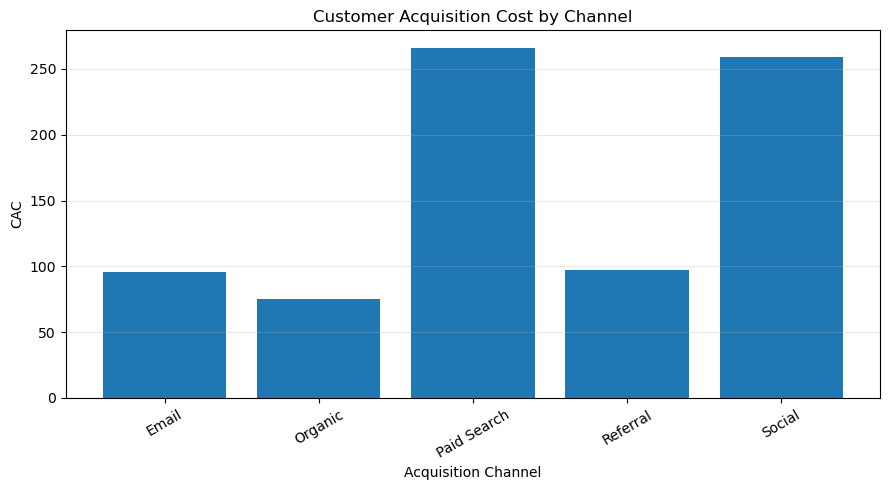

In [43]:
cac_by_channel = (
    cac_df.groupby("channel", as_index=False)
    .agg(
        total_spend=("spend", "sum"),
        total_customers=("new_customers", "sum")
    )
)

cac_by_channel["cac"] = (
    cac_by_channel["total_spend"] /
    cac_by_channel["total_customers"]
)

display(cac_by_channel.sort_values("cac"))

plt.figure(figsize=(9, 5))
plt.bar(cac_by_channel["channel"], cac_by_channel["cac"])
plt.title("Customer Acquisition Cost by Channel")
plt.xlabel("Acquisition Channel")
plt.ylabel("CAC")
plt.xticks(rotation=30)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [44]:
with engine.connect() as conn:
    churn_df = pd.read_sql(
        text("SELECT * FROM vw_churn ORDER BY month"),
        conn
    )

display(churn_df[churn_df["churn_rate"].isna()])

,month,cancelled_subscriptions,starting_subscriptions,churn_rate
0,2023-11,0,0,NaN


In [45]:
print("Missing churn rates:", churn_df["churn_rate"].isna().sum())
print("Total months:", len(churn_df))

Missing churn rates: 1
Total months: 36


In [46]:
display(
    churn_df[churn_df["churn_rate"].isna()][
        [
            "month",
            "cancelled_subscriptions",
            "starting_subscriptions",
            "churn_rate"
        ]
    ]
)

,month,cancelled_subscriptions,starting_subscriptions,churn_rate
0,2023-11,0,0,NaN


In [47]:
print(
    churn_df.loc[
        churn_df["churn_rate"].isna(),
        ["month", "starting_subscriptions", "cancelled_subscriptions"]
    ].to_string(index=False)
)

  month  starting_subscriptions  cancelled_subscriptions
2023-11                       0                        0


In [48]:
display(
    churn_df[churn_df["month"].astype(str).str.startswith("2023-11")]
)

,month,cancelled_subscriptions,starting_subscriptions,churn_rate
0,2023-11,0,0,NaN


In [49]:
with engine.connect() as conn:
    result = conn.execute(
        text("SHOW CREATE VIEW vw_churn")
    ).fetchone()

print(result[1])

CREATE ALGORITHM=UNDEFINED DEFINER=`saas_user`@`localhost` SQL SECURITY DEFINER VIEW `vw_churn` AS select date_format(`m`.`month_start`,'%Y-%m') AS `month`,count(distinct (case when ((`s`.`end_date` >= `m`.`month_start`) and (`s`.`end_date` < (`m`.`month_start` + interval 1 month))) then `s`.`subscription_id` end)) AS `cancelled_subscriptions`,count(distinct (case when ((`s`.`start_date` < `m`.`month_start`) and ((`s`.`end_date` is null) or (`s`.`end_date` >= `m`.`month_start`))) then `s`.`subscription_id` end)) AS `starting_subscriptions`,round(((100.0 * count(distinct (case when ((`s`.`end_date` >= `m`.`month_start`) and (`s`.`end_date` < (`m`.`month_start` + interval 1 month))) then `s`.`subscription_id` end))) / nullif(count(distinct (case when ((`s`.`start_date` < `m`.`month_start`) and ((`s`.`end_date` is null) or (`s`.`end_date` >= `m`.`month_start`))) then `s`.`subscription_id` end)),0)),2) AS `churn_rate` from ((select distinct date_format(`subscriptions`.`start_date`,'%Y-%m-0

In [50]:
from sqlalchemy import text
import pandas as pd

with engine.begin() as conn:
    conn.execute(text("""
        CREATE OR REPLACE VIEW vw_churn AS
        SELECT
            DATE_FORMAT(m.month_start, '%Y-%m') AS month,

            COUNT(DISTINCT CASE
                WHEN s.end_date >= m.month_start
                 AND s.end_date < DATE_ADD(m.month_start, INTERVAL 1 MONTH)
                THEN s.subscription_id
            END) AS cancelled_subscriptions,

            COUNT(DISTINCT CASE
                WHEN s.start_date < DATE_ADD(m.month_start, INTERVAL 1 MONTH)
                 AND (
                     s.end_date IS NULL
                     OR s.end_date >= DATE_ADD(m.month_start, INTERVAL 1 MONTH)
                 )
                THEN s.subscription_id
            END) AS starting_subscriptions,

            ROUND(
                100.0 * COUNT(DISTINCT CASE
                    WHEN s.end_date >= m.month_start
                     AND s.end_date < DATE_ADD(m.month_start, INTERVAL 1 MONTH)
                    THEN s.subscription_id
                END)
                /
                NULLIF(
                    COUNT(DISTINCT CASE
                        WHEN s.start_date < DATE_ADD(m.month_start, INTERVAL 1 MONTH)
                         AND (
                             s.end_date IS NULL
                             OR s.end_date >= DATE_ADD(m.month_start, INTERVAL 1 MONTH)
                         )
                        THEN s.subscription_id
                    END),
                    0
                ),
                2
            ) AS churn_rate

        FROM (
            SELECT DISTINCT
                DATE_FORMAT(start_date, '%Y-%m-01') AS month_start
            FROM subscriptions

            UNION

            SELECT DISTINCT
                DATE_FORMAT(end_date, '%Y-%m-01') AS month_start
            FROM subscriptions
            WHERE end_date IS NOT NULL
        ) AS m

        LEFT JOIN subscriptions AS s
            ON s.start_date < DATE_ADD(m.month_start, INTERVAL 1 MONTH)

        GROUP BY m.month_start
    """))

print("vw_churn updated successfully.")

vw_churn updated successfully.


In [51]:
with engine.connect() as conn:
    churn_df = pd.read_sql(
        text("SELECT * FROM vw_churn ORDER BY month"),
        conn
    )

display(churn_df.head(5))

print("Total months:", len(churn_df))
print("Missing churn rates:", churn_df["churn_rate"].isna().sum())
print("Missing starting counts:", churn_df["starting_subscriptions"].isna().sum())

,month,cancelled_subscriptions,starting_subscriptions,churn_rate
0,2023-11,0,157,0.00
1,2023-12,4,332,1.20
2,2024-01,4,555,0.72
3,2024-02,15,746,2.01
4,2024-03,16,934,1.71


Total months: 36
Missing churn rates: 0
Missing starting counts: 0


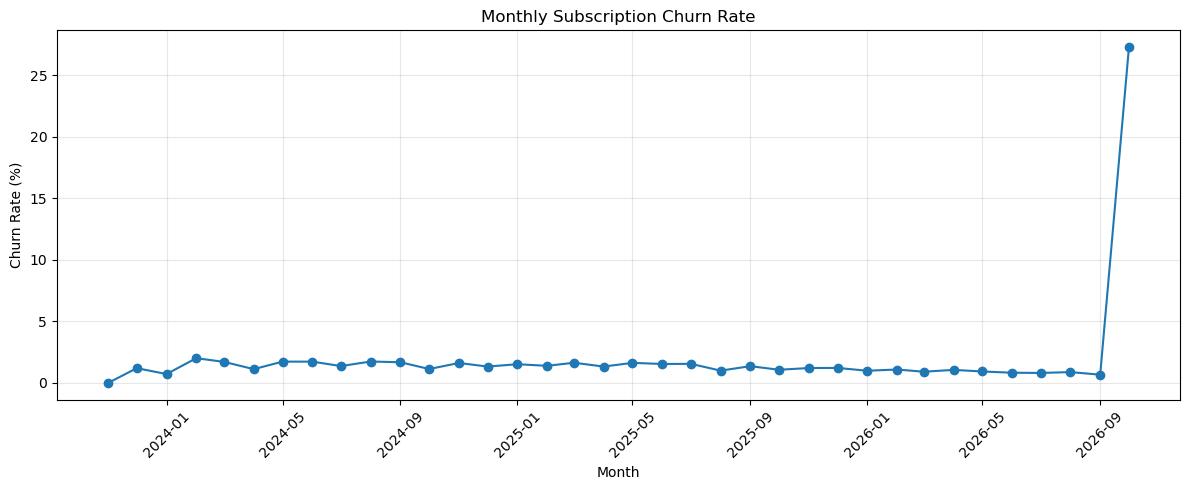

In [52]:
import matplotlib.pyplot as plt

churn_df["month"] = pd.to_datetime(churn_df["month"])

plt.figure(figsize=(12, 5))
plt.plot(
    churn_df["month"],
    churn_df["churn_rate"],
    marker="o"
)

plt.title("Monthly Subscription Churn Rate")
plt.xlabel("Month")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [53]:
print("Total months:", len(churn_df))
print("Missing churn rates:", churn_df["churn_rate"].isna().sum())

display(
    churn_df.sort_values("churn_rate", ascending=False).head(5)
)

Total months: 36
Missing churn rates: 0


,month,cancelled_subscriptions,starting_subscriptions,churn_rate
35,2026-10-01,1830,6707,27.28
3,2024-02-01,15,746,2.01
9,2024-08-01,35,2013,1.74
6,2024-05-01,24,1384,1.73
7,2024-06-01,28,1616,1.73


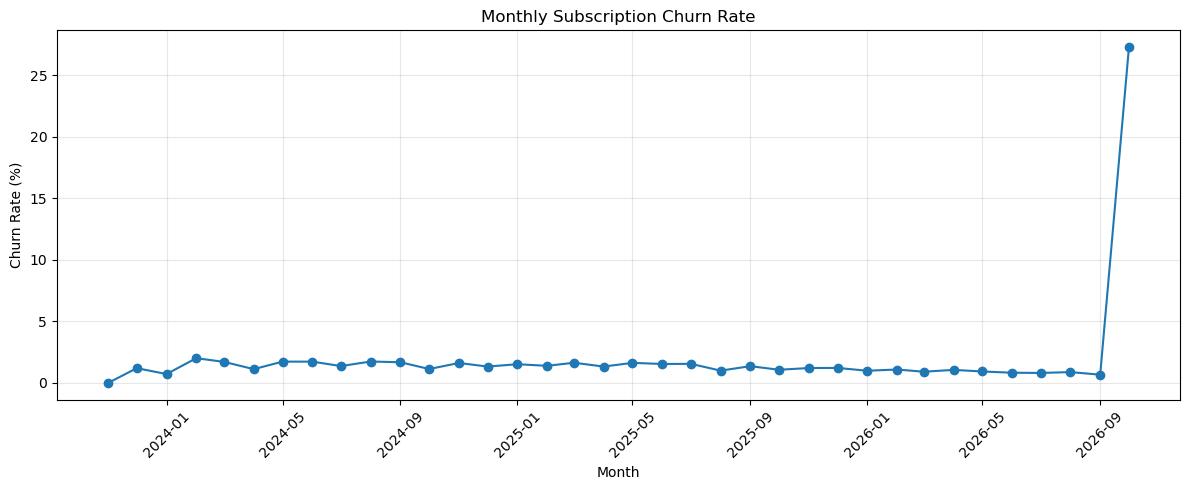

In [54]:
plt.figure(figsize=(12, 5))

plt.plot(
    churn_df["month"],
    churn_df["churn_rate"],
    marker="o"
)

plt.title("Monthly Subscription Churn Rate")
plt.xlabel("Month")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig("monthly_churn_rate.png", dpi=300, bbox_inches="tight")
plt.show()